# Notebook 01 - Eksplorasi dan profiling data

Notebook ini memakai Pandas pada sampel 100.000 baris untuk memahami schema dan kualitas data. Insight akhir tidak boleh disimpulkan hanya dari sampel awal ini.

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next((
    folder for folder in (CURRENT_DIR, *CURRENT_DIR.parents)
    if (folder / 'src').is_dir() and (folder / 'README.md').is_file()
), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Root proyek tidak ditemukan. Jalankan Jupyter dari folder repository.')
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import get_paths, validate_source_files

paths = get_paths('retail_contaminated_dataset')
validate_source_files(paths)
paths.source_dir

WindowsPath('D:/Latihan_Aiman/S5/560_BIG DATA/Project UTS/Synthetic Retail Dataset - 10 Million Transactions/retail_contaminated_dataset')

## 1. Membaca sampel transaksi dan tabel master

In [2]:
SAMPLE_ROWS = 100_000
sales = pd.read_csv(
    paths.source_dir / 'sales_transactions.csv',
    nrows=SAMPLE_ROWS,
    parse_dates=['date'],
)
stores = pd.read_csv(paths.source_dir / 'store_master.csv', parse_dates=['opening_date'])
skus = pd.read_csv(paths.source_dir / 'sku_master.csv')
customers = pd.read_csv(
    paths.source_dir / 'customer_master.csv', parse_dates=['registration_date']
)
promotions = pd.read_csv(
    paths.source_dir / 'promotions.csv', parse_dates=['start_date', 'end_date']
)
inventory = pd.read_csv(
    paths.source_dir / 'inventory_snapshot.csv', parse_dates=['last_restock_date']
)
flags = pd.read_csv(
    paths.source_dir / 'sku_inventory_flags.csv',
    parse_dates=['window_start', 'window_end'],
)

print(f'Sampel transaksi: {len(sales):,} baris')
display(sales.head())

Sampel transaksi: 100,000 baris


,date,receipt_id,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct,promo_id
0,2025-04-02,RCPT00000001,ST16,SKU02498,CUST01410,1,2379.11,2379.11,In-Store,0.0,NaN
1,2025-04-02,RCPT00000001,ST16,SKU04596,CUST01410,3,335.55,1006.65,In-Store,0.0,NaN
2,2022-04-24,RCPT00000002,ST15,SKU00078,CUST00134,1,820.53,820.53,Online,0.0,NaN
3,2022-04-24,RCPT00000002,ST15,SKU00554,CUST00134,2,88.32,176.64,Online,0.0,NaN
4,2024-09-22,RCPT00000003,ST20,SKU03727,CUST08826,1,1660.93,1660.93,Online,0.0,NaN


## 2. Ringkasan tabel dan schema

In [3]:
tables = {
    'sales_sample': sales,
    'stores': stores,
    'skus': skus,
    'customers': customers,
    'promotions': promotions,
    'inventory': inventory,
    'flags': flags,
}
overview = pd.DataFrame([
    {
        'table': name,
        'rows': len(frame),
        'columns': frame.shape[1],
        'duplicate_rows': int(frame.duplicated().sum()),
        'missing_cells': int(frame.isna().sum().sum()),
    }
    for name, frame in tables.items()
])
display(overview)
display(pd.DataFrame({'dtype': sales.dtypes.astype(str), 'missing': sales.isna().sum()}))

,table,rows,columns,duplicate_rows,missing_cells
0,sales_sample,100000,11,136,79254
1,stores,30,5,0,0
2,skus,5000,7,0,0
3,customers,10000,7,0,0
4,promotions,100,8,0,0
5,inventory,26408,6,0,0
6,flags,600,6,0,800


,dtype,missing
date,datetime64[ns],0
receipt_id,object,0
store_id,object,0
sku_id,object,0
customer_id,object,0
quantity,int64,0
unit_price,float64,0
total_value,float64,0
channel,object,0
discount_pct,float64,0


## 3. Quality checks pada sampel

`promo_id` boleh kosong karena tidak semua transaksi memakai promosi.

In [4]:
required = [
    'date', 'receipt_id', 'store_id', 'sku_id', 'customer_id',
    'quantity', 'unit_price', 'total_value', 'channel', 'discount_pct'
]
calculated_total = (
    sales['quantity'] * sales['unit_price'] * (1 - sales['discount_pct'] / 100)
).round(2)
checks = {
    'sample_rows_100k': len(sales) == 100_000,
    'required_fields_complete': not sales[required].isna().any().any(),
    'quantity_positive': sales['quantity'].gt(0).all(),
    'price_nonnegative': sales['unit_price'].ge(0).all(),
    'discount_in_range': sales['discount_pct'].between(0, 100).all(),
    'total_value_formula': np.allclose(
        sales['total_value'], calculated_total, atol=0.02
    ),
    'store_keys_valid': sales['store_id'].isin(stores['store_id']).all(),
    'sku_keys_valid': sales['sku_id'].isin(skus['sku_id']).all(),
    'customer_keys_valid': sales['customer_id'].isin(customers['cust_id']).all(),
    'nonblank_promo_keys_valid': sales.loc[
        sales['promo_id'].notna(), 'promo_id'
    ].isin(promotions['promo_id']).all(),
}
check_table = pd.DataFrame({'check': checks.keys(), 'passed': checks.values()})
display(check_table)
assert check_table['passed'].all(), 'Ada quality check sampel yang gagal.'

,check,passed
0,sample_rows_100k,True
1,required_fields_complete,True
2,quantity_positive,True
3,price_nonnegative,True
4,discount_in_range,True
5,total_value_formula,True
6,store_keys_valid,True
7,sku_keys_valid,True
8,customer_keys_valid,True
9,nonblank_promo_keys_valid,True


## 4. Join dan kolom turunan

In [5]:
store_dim = stores.rename(columns={'city': 'store_city'})
sku_dim = skus.rename(columns={'unit_price': 'list_unit_price'})
customer_dim = customers.rename(
    columns={'cust_id': 'customer_id', 'city': 'customer_city'}
)
eda = (
    sales.merge(store_dim, on='store_id', how='left', validate='many_to_one')
    .merge(sku_dim, on='sku_id', how='left', validate='many_to_one')
    .merge(customer_dim, on='customer_id', how='left', validate='many_to_one')
)
eda['month'] = eda['date'].dt.to_period('M').dt.to_timestamp()
eda['gross_sales'] = (eda['quantity'] * eda['unit_price']).round(2)
eda['discount_amount'] = (eda['gross_sales'] - eda['total_value']).round(2)
eda['gross_profit'] = (
    eda['total_value'] - eda['quantity'] * eda['cost_price']
).round(2)
display(eda.head())

,date,receipt_id,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct,...,age,gender,customer_city,loyalty_segment,preferred_channel,registration_date,month,gross_sales,discount_amount,gross_profit
0,2025-04-02,RCPT00000001,ST16,SKU02498,CUST01410,1,2379.11,2379.11,In-Store,0.0,...,47,Female,Islamabad,Gold,In-Store,2020-09-29,2025-04-01,2379.11,0.0,751.20
1,2025-04-02,RCPT00000001,ST16,SKU04596,CUST01410,3,335.55,1006.65,In-Store,0.0,...,47,Female,Islamabad,Gold,In-Store,2020-09-29,2025-04-01,1006.65,0.0,278.28
2,2022-04-24,RCPT00000002,ST15,SKU00078,CUST00134,1,820.53,820.53,Online,0.0,...,62,Female,Islamabad,Gold,Online,2025-10-12,2022-04-01,820.53,0.0,167.07
3,2022-04-24,RCPT00000002,ST15,SKU00554,CUST00134,2,88.32,176.64,Online,0.0,...,62,Female,Islamabad,Gold,Online,2025-10-12,2022-04-01,176.64,0.0,77.32
4,2024-09-22,RCPT00000003,ST20,SKU03727,CUST08826,1,1660.93,1660.93,Online,0.0,...,51,Male,Lahore,Gold,Online,2022-07-10,2024-09-01,1660.93,0.0,369.75


## 5. Visualisasi eksplorasi sampel

Grafik berikut hanya untuk memahami struktur sampel. Grafik final dibuat dari agregasi data penuh pada Notebook 03.

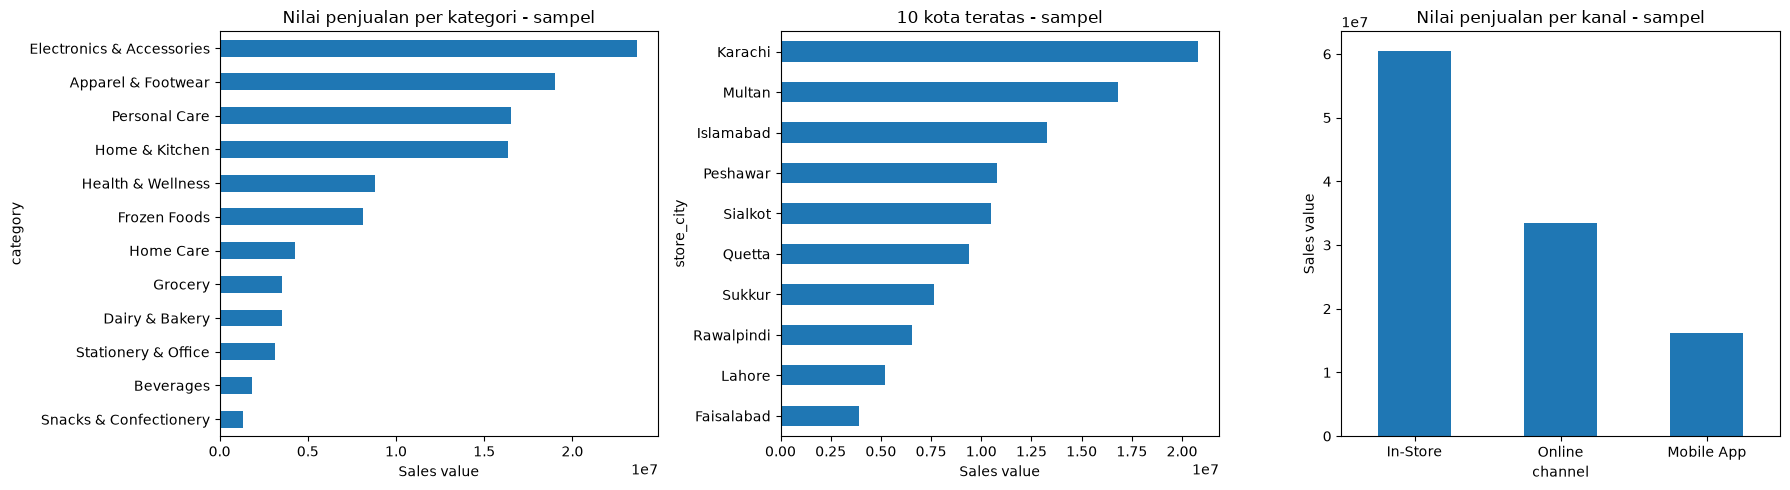

In [6]:
paths.charts_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
eda.groupby('category')['total_value'].sum().sort_values().plot.barh(ax=axes[0])
axes[0].set_title('Nilai penjualan per kategori - sampel')
axes[0].set_xlabel('Sales value')

eda.groupby('store_city')['total_value'].sum().nlargest(10).sort_values().plot.barh(ax=axes[1])
axes[1].set_title('10 kota teratas - sampel')
axes[1].set_xlabel('Sales value')

eda.groupby('channel')['total_value'].sum().sort_values(ascending=False).plot.bar(ax=axes[2])
axes[2].set_title('Nilai penjualan per kanal - sampel')
axes[2].set_ylabel('Sales value')
axes[2].tick_params(axis='x', rotation=0)

fig.tight_layout()
fig.savefig(paths.charts_dir / '00_sample_exploration.png', dpi=150, bbox_inches='tight')
plt.show()

## Kesimpulan sementara

Tuliskan temuan mengenai schema, kualitas teknis, kolom yang perlu diturunkan, dan alasan data penuh diproses dengan PySpark. Jangan menuliskan insight bisnis final dari sampel awal.